# Landing ports in Jamaica: Kingston and Montego Bay

Did people from different parts of Africa end up in different parts of Jamaica? The voyage
database cannot say where anyone lived, but it does record the port where captives were
landed, and in the late eighteenth century Jamaica had a second major port of arrival on the
north coast: Montego Bay, which served the north-western parishes (St James, Hanover,
Trelawny and Westmoreland). This notebook compares it with Kingston.

Numbers are imputed people disembarked, by the voyage's imputed principal region of
embarkation; the landing port is the principal place of disembarkation, recorded for almost
every voyage here. A check with recorded places only follows.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()
jamaica = v.transatlantic.disembarked_in("Jamaica")
rows = jamaica.to_pandas(
    [
        "voyage_id",
        "disembarkation_place_name",
        "disembarkation_provenance",
        "embarkation_region_name",
        "embarkation_place_name",
        "departure_place_imputed_name",
        "year_arrived_imputed",
        "disembarked_imputed",
    ]
)

## The ports

Every place of landing in Jamaica in the database, with its first and last year.

In [2]:
ports = (
    rows.groupby("disembarkation_place_name")
    .agg(
        voyages=("voyage_id", "size"),
        people=("disembarked_imputed", "sum"),
        first=("year_arrived_imputed", "min"),
        last=("year_arrived_imputed", "max"),
    )
    .sort_values("voyages", ascending=False)
)
ports

,voyages,people,first,last
disembarkation_place_name,,,,
"Jamaica, port unspecified",1715,413384,1588,1839
Kingston,1622,452007,1670,1857
Montego Bay,144,43263,1763,1808
Port Royal,30,7354,1693,1800
Savanna la Mar,18,3981,1751,1806
Black River,9,2235,1781,1793
Falmouth (Jam.),9,2341,1792,1808
Lucea,9,2031,1775,1793
Port Maria,9,2521,1685,1793


In [3]:
rows.disembarkation_provenance.value_counts()

disembarkation_provenance
recorded    3516
imputed       75
Name: count, dtype: int64

Kingston, and before it Port Royal, was the island's main market. Nearly half the voyages
name no port ("Jamaica, port unspecified"). Montego Bay is the only other port with more
than a few dozen voyages, all between 1763 and 1808, when Britain abolished its slave trade.

## Kingston and Montego Bay, 1763–1808

The comparison keeps to Montego Bay's years, so that both ports are measured against the
same trade. Regions are grouped: "Upper Guinea" is Senegambia, Sierra Leone and the
Windward Coast.

In [4]:
REGION = {
    "Senegambia and offshore Atlantic": "Upper Guinea",
    "Sierra Leone": "Upper Guinea",
    "Windward Coast": "Upper Guinea",
    "Gold Coast": "Gold Coast",
    "Bight of Benin": "Bight of Benin",
    "Bight of Biafra and Gulf of Guinea islands": "Bight of Biafra",
    "West Central Africa and St. Helena": "West Central Africa",
}
ORDER = [
    "Bight of Biafra",
    "Gold Coast",
    "West Central Africa",
    "Bight of Benin",
    "Upper Guinea",
    "Other or not known",
]
PORT_ORDER = ["Kingston", "Montego Bay", "Other named ports", "Jamaica, port unspecified"]

window = rows[rows.year_arrived_imputed.between(1763, 1808)].copy()
window["region"] = pd.Categorical(
    window.embarkation_region_name.map(REGION).fillna("Other or not known"), ORDER
)
window["port"] = window.disembarkation_place_name.where(
    window.disembarkation_place_name.isin(PORT_ORDER), "Other named ports"
)
people = (
    window.pivot_table(
        index="port", columns="region", values="disembarked_imputed", aggfunc="sum",
        observed=False,
    )
    .reindex(PORT_ORDER)
    .fillna(0)
    .astype(int)
)  # fmt: skip
mix = (people.div(people.sum(axis=1), axis=0) * 100).round(1)
mix.assign(people=people.sum(axis=1), voyages=window.groupby("port").size())

region,Bight of Biafra,Gold Coast,West Central Africa,Bight of Benin,Upper Guinea,Other or not known,people,voyages
port,,,,,,,,
Kingston,34.9,24.6,20.5,7.7,7.3,4.8,289939,951
Montego Bay,68.3,15.4,0.0,2.9,9.5,3.9,43263,144
Other named ports,27.7,31.1,3.9,5.1,20.8,11.4,17825,77
"Jamaica, port unspecified",30.0,24.2,5.7,6.8,13.4,19.9,133404,512


Over the same years, about two-thirds of the people landed at Montego Bay came from the
Bight of Biafra, against about a third at Kingston. Kingston took a fifth of its people from
West Central Africa (Kongo and Angola); Montego Bay almost none.

The difference holds within shorter spans, so it is not just that Montego Bay's voyages fall
in years when the Biafran trade was larger:

In [5]:
SPANS = pd.IntervalIndex.from_breaks([1762, 1780, 1795, 1808])
two = window[window.port.isin(["Kingston", "Montego Bay"])].assign(
    span=lambda d: pd.cut(d.year_arrived_imputed, SPANS)
)
biafra_share = (
    two.groupby(["span", "port"], observed=True)
    .apply(
        lambda g: pd.Series(
            {
                "voyages": len(g),
                "from Biafra (%)": round(
                    g.loc[g.region == "Bight of Biafra", "disembarked_imputed"].sum()
                    / g.disembarked_imputed.sum()
                    * 100,
                    1,
                ),
            }
        )
    )
    .unstack("port")
)
biafra_share.index = ["1763–1780", "1781–1795", "1796–1808"]
biafra_share

voyages             from Biafra (%)            
port      Kingston Montego Bay        Kingston Montego Bay
1763–1780    217.0        34.0            19.5        42.5
1781–1795    352.0        88.0            29.3        72.4
1796–1808    382.0        22.0            47.6        83.8

Where Montego Bay's ships loaded their captives, and where they sailed from. Bonny
dominates, followed by New Calabar and Old Calabar; most ships were from Liverpool and
Bristol.

In [6]:
montego = window[window.port == "Montego Bay"]
montego_african_ports = (
    montego.groupby("embarkation_place_name").disembarked_imputed.sum().nlargest(5).astype(int)
)
montego_african_ports

embarkation_place_name
Bonny                                                           20849
New Calabar                                                      3825
Anomabu, Adja, Agga                                              3161
Calabar                                                          2594
Bight of Biafra and Gulf of Guinea Islands, port unspecified     1719
Name: disembarked_imputed, dtype: int64

In [7]:
home_ports = (
    window[window.port.isin(["Kingston", "Montego Bay"])]
    .groupby(["departure_place_imputed_name", "port"])
    .size()
    .unstack("port", fill_value=0)
    .sort_values("Kingston", ascending=False)
    .head(5)
)
home_ports

port,Kingston,Montego Bay
departure_place_imputed_name,,
Liverpool,688,90
London,135,18
Bristol,66,28
Whitehaven,15,0
Lancaster,11,0


## Check with recorded places only

The same comparison using only what the records say: the recorded principal place of
landing, the recorded principal region of purchase, and voyages counted rather than people,
so no imputed number is used. (Recorded years: the voyages are kept if their recorded year
of arrival falls in 1763–1808.)

In [8]:
recorded = (
    v.transatlantic.recorded_only()
    .disembarked_in("Kingston", "Montego Bay")
    .to_pandas(["voyage_id", "disembarkation_place_name", "embarkation_region_name"])
    .merge(
        v.sql(
            "SELECT voyage_id, first_landing_year FROM voyages_wide WHERE dataset = 'transatlantic'"
        ).to_pandas(),
        on="voyage_id",
    )
)
recorded = recorded[recorded.first_landing_year.between(1763, 1808)]
recorded_share = recorded.groupby("disembarkation_place_name").apply(
    lambda g: pd.Series(
        {
            "voyages with a recorded region": int(g.embarkation_region_name.notna().sum()),
            "from Biafra (%)": round(
                (g.embarkation_region_name == "Bight of Biafra and Gulf of Guinea islands").sum()
                / g.embarkation_region_name.notna().sum()
                * 100,
                1,
            ),
        }
    )
)
recorded_share

,voyages with a recorded region,from Biafra (%)
disembarkation_place_name,,
Kingston,857.0,33.5
Montego Bay,132.0,63.6


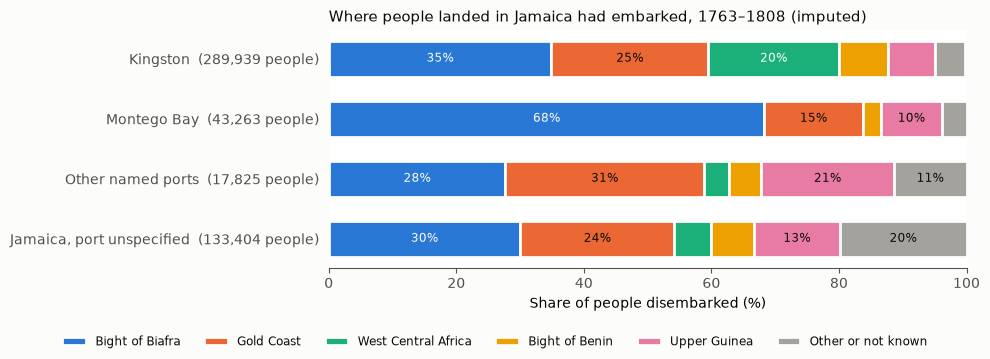

In [9]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3dd"
COLOURS = dict(
    zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#a3a29c"], strict=True)
)
DARK = {"Bight of Biafra", "West Central Africa"}  # white labels only on these fills
plt.rcParams.update({"figure.facecolor": SURFACE, "text.color": INK, "font.size": 10})

fig, ax = plt.subplots(figsize=(10, 3.6))
labels = [f"{p}  ({people.loc[p].sum():,} people)" for p in PORT_ORDER]
left = pd.Series(0.0, index=PORT_ORDER)
for region in ORDER:
    ax.barh(
        labels, mix[region], left=left, color=COLOURS[region], edgecolor=SURFACE,
        linewidth=2, label=region, height=0.6,
    )  # fmt: skip
    for i, port in enumerate(PORT_ORDER):
        if mix.loc[port, region] >= 8:
            ax.text(
                left[port] + mix.loc[port, region] / 2, i, f"{mix.loc[port, region]:.0f}%",
                ha="center", va="center", fontsize=8.5,
                color=SURFACE if region in DARK else INK,
            )  # fmt: skip
    left += mix[region]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of people disembarked (%)")
ax.set_title(
    "Where people landed in Jamaica had embarked, 1763–1808 (imputed)", loc="left", fontsize=11
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(colors=MUTED, left=False)
fig.legend(frameon=False, fontsize=8.5, ncol=6, loc="lower center")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig("figures/06_port_origins.png", dpi=150)

## What this can and cannot show

- **The landing port is not where people lived.** Planters from every parish bought at
  Kingston, and many people landed there were shipped on to other colonies (notebook 03).
  Montego Bay's buyers were mostly from the north-western parishes, so the pattern suggests
  that the African-born people of St James, Hanover, Trelawny and Westmoreland in the late
  eighteenth century were more often from the Bight of Biafra (Igbo and Ibibio country) than
  those of the south and east. That is an inference, not a measurement.
- **Nearly half the voyages name no port**, so the comparison rests on the ones that do.
- **The other ports are small.** Savanna-la-Mar, Lucea, Falmouth, Black River, Port Maria and
  the rest have fewer than 20 voyages each, too few for their mix to mean much.

Records that do name a person's parish or estate, such as runaway notices in Jamaican
newspapers and the slave registers of 1817–1834, are outside this database.

## Checks

The figures quoted above, checked against the tables.

In [10]:
assert ports.index[:3].tolist() == ["Jamaica, port unspecified", "Kingston", "Montego Bay"]
assert (ports.loc["Montego Bay", "first"], ports.loc["Montego Bay", "last"]) == (1763, 1808)
assert (ports.drop(index=ports.index[:4]).voyages < 20).all()
assert (rows.disembarkation_provenance == "recorded").mean() > 0.97
assert 0.45 < (rows.disembarkation_place_name == "Jamaica, port unspecified").mean() < 0.5
assert 64 <= mix.loc["Montego Bay", "Bight of Biafra"] <= 70
assert 30 <= mix.loc["Kingston", "Bight of Biafra"] <= 37
assert 18 <= mix.loc["Kingston", "West Central Africa"] <= 23
assert mix.loc["Montego Bay", "West Central Africa"] < 1
assert (
    biafra_share["from Biafra (%)", "Montego Bay"] > biafra_share["from Biafra (%)", "Kingston"]
).all()
assert montego_african_ports.index[:2].tolist() == ["Bonny", "New Calabar"]
assert "Calabar" in montego_african_ports.index
assert montego.departure_place_imputed_name.value_counts().index[:2].tolist() == [
    "Liverpool",
    "Bristol",
]
assert (
    recorded_share.loc["Montego Bay", "from Biafra (%)"]
    > 1.5 * recorded_share.loc["Kingston", "from Biafra (%)"]
)

In [11]:
voyages.citation()

'SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).'